# CS-117 · Animal Video Re-ID

**Sources:** [PolarBearVidID dataset](https://zenodo.org/records/7564529) · [dataset paper](https://doi.org/10.3390/ani13050801) · [MegaDescriptor-S model card](https://huggingface.co/BVRA/MegaDescriptor-S-224)

## 1. Install dependencies

`timm` loads the pretrained Swin model. This dependency installation is based on the [official timm project](https://github.com/huggingface/pytorch-image-models); the model-loading call in Step 5 follows the [MegaDescriptor model card](https://huggingface.co/BVRA/MegaDescriptor-S-224).

In [ ]:
%pip -q install "timm>=1.0,<2" "huggingface_hub>=0.25"

In [ ]:
import json, math, random, zipfile, io, re
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", DEVICE, "| torch:", torch.__version__)

Running on: cpu | torch: 2.14.1+cpu


### 1b. MegaDescriptor smoke test

Run this one cell after installation/imports. It follows the [MegaDescriptor-S official model-card image-embedding example](https://huggingface.co/BVRA/MegaDescriptor-S-224), using its model identifier, pretrained weights, mean/std normalization, and public example image. **Small documented adaptation:** resize to **exactly** 224×224, because the Swin model expects a square input; the card uses `Resize(224)`, which preserves aspect ratio.

**Important:** This is an inference smoke test, not a Rank-1 accuracy result. A successful output confirms the official pretrained feature extractor runs on Colab environment.

#### 1b.1 Load pretrained weights and process one image

Run this cell and inspect its printed status before moving to the next one. The next cell reuses variables created here.

In [ ]:
import timm
import platform
import torch
import torchvision.transforms as T
from PIL import Image
from urllib.request import urlopen

SMOKE_MODEL_ID = "hf-hub:BVRA/MegaDescriptor-S-224"
smoke_model = timm.create_model(SMOKE_MODEL_ID, pretrained=True)
smoke_model = smoke_model.eval()
smoke_transform = T.Compose([T.Resize(224),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
smoke_image = Image.open(urlopen(
    'https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/beignets-task-guide.png'
))
smoke_input = smoke_transform(smoke_image).unsqueeze(0)
smoke_output = smoke_model(smoke_input)
print('Model-card example completed. Output shape:', tuple(smoke_output.shape))

config.json:   0%|          | 0.00/610 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  290MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Model-card example completed. Output shape: (1, 768)


#### 1b.2 Prepare the 15-line Slide 4 report

Run this cell and inspect its printed status before moving to the next one. The next cell reuses variables created here.

In [ ]:
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU used"
slide4_lines = [
    "MegaDescriptor-S official model-card example (original Resize(224))",
    "Source: https://huggingface.co/BVRA/MegaDescriptor-S-224",
    f"Command: timm.create_model({SMOKE_MODEL_ID!r}, pretrained=True)",
    f"Runtime: {'Google Colab' if 'google.colab' in __import__('sys').modules else 'Jupyter/Python'}",
    f"Python: {platform.python_version()}",
    f"PyTorch: {torch.__version__}",
    f"timm: {timm.__version__}",
    "Device: CPU (model-card inference, unchanged)",
    f"GPU: {gpu_name}",
    "Pretrained weights: loaded successfully",
    f"Example image: downloaded from official model-card URL ({smoke_image.size})",
    f"Input tensor: {tuple(smoke_input.shape)}",
    f"Embedding tensor: {tuple(smoke_output.shape)}",
    f"Embedding values finite: {bool(torch.isfinite(smoke_output).all())}",
    "RESULT: PASS - pretrained model inference successful",
]
slide4_text = "\n".join(slide4_lines)

#### 1b.3 Display and save the Slide 4 report

Run this cell and inspect its printed status before moving to the next one. The next cell reuses variables created here.

In [ ]:
print(slide4_text)
del smoke_model, smoke_input, smoke_output
if torch.cuda.is_available():
    torch.cuda.empty_cache()

MegaDescriptor-S official model-card example (original Resize(224))
Source: https://huggingface.co/BVRA/MegaDescriptor-S-224
Command: timm.create_model('hf-hub:BVRA/MegaDescriptor-S-224', pretrained=True)
Runtime: Google Colab
Python: 3.13.18
PyTorch: 2.14.1+cpu
timm: 1.0.31
Device: CPU (model-card inference, unchanged)
GPU: No GPU used
Pretrained weights: loaded successfully
Example image: downloaded from official model-card URL ((512, 512))
Input tensor: (1, 3, 224, 224)
Embedding tensor: (1, 768)
Embedding values finite: True
RESULT: PASS - pretrained model inference successful


## 2. RQ1 baseline: download the full dataset and configure evaluation

The notebook **automatically downloads the official PolarBearVidID ZIP (~1.6 GB)** from [Zenodo record 7564529](https://zenodo.org/records/7564529) into Colab's temporary disk.

### Download Dataset

Run this cell and inspect its printed status before moving to the next one. The next cell reuses variables created here.

In [ ]:
LOCAL_ZIP = Path("/content/PolarBearVidID.zip")
DATASET_URL = "https://zenodo.org/records/7564529/files/PolarBearVidID.zip?download=1"
DATASET_MD5 = "96ab1d0dbe47624741955f566e69c833"  # official Zenodo checksum
OUTPUT_DIR = Path("/content/reid_results")
FRAMES_PER_VIDEO = 20          # fixed candidate pool, reusable for RQ2
FRAME_COUNTS = [1, 2, 4, 8, 16, 20]
SEEDS = [0, 1, 2, 3, 4]
BATCH_SIZE = 32 if DEVICE == "cuda" else 8
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
import hashlib, requests
from tqdm.auto import tqdm
def file_md5(path):
    digest = hashlib.md5()  # compares against the dataset publisher's checksum
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()
print("ready")

ready


In [ ]:
if LOCAL_ZIP.is_file() and file_md5(LOCAL_ZIP) == DATASET_MD5:
    print("Using verified existing dataset:", LOCAL_ZIP)
else:
    print("Downloading official PolarBearVidID dataset from Zenodo (~1.6 GB)...")
    partial_path = LOCAL_ZIP.with_suffix(".zip.part")
    with requests.get(DATASET_URL, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))
        with open(partial_path, "wb") as handle, tqdm(total=total or None, unit="B", unit_scale=True, desc="PolarBearVidID") as bar:
            for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
                if chunk:
                    handle.write(chunk)
                    bar.update(len(chunk))
    if file_md5(partial_path) != DATASET_MD5:
        raise RuntimeError("Download checksum mismatch. Re-run this cell to retry the official archive.")
    partial_path.replace(LOCAL_ZIP)
    print("Download complete and checksum verified.")
print("Archive:", LOCAL_ZIP, "bytes:", LOCAL_ZIP.stat().st_size)

PolarBearVidID:   0%|          | 0.00/1.57G [00:00<?, ?B/s]

Download complete and checksum verified.
Archive: /content/PolarBearVidID.zip bytes: 1573948301


### Dataset structure inspection

Identity means **which bear**; sequence means **which separate short video of that bear**. We print representative paths and parse the observed filename pattern in the next cell.

In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

with zipfile.ZipFile(LOCAL_ZIP) as archive:
    members = sorted(
        x for x in archive.namelist()
        if not x.endswith("/") and Path(x).suffix.lower() in IMAGE_EXTENSIONS
        and not x.startswith("__MACOSX/")
    )

print("Image members:", len(members))
print("First 12 ZIP paths:")
for path in members[:12]:
    print(" ", path)
print("Different path depths:", Counter(len(Path(x).parts) for x in members))
assert members, "No image frames found. The archive may use video files or an unexpected format. Stop and inspect it."

Image members: 138363
First 12 ZIP paths:
  000/000C01T000F000.jpg
  000/000C01T000F001.jpg
  000/000C01T000F002.jpg
  000/000C01T000F003.jpg
  000/000C01T000F004.jpg
  000/000C01T000F005.jpg
  000/000C01T000F006.jpg
  000/000C01T000F007.jpg
  000/000C01T000F008.jpg
  000/000C01T000F009.jpg
  000/000C01T000F010.jpg
  000/000C01T000F011.jpg
Different path depths: Counter({2: 138363})


### Parse PolarBearVidID's actual filename layout

The actual archive includes paths like `000/000C01T000F000.jpg`.

- The folder `000` is treated as the bear identity.
- The filename prefix `000C01T000` (everything before the final `F` plus frame digits) is treated as the video sequence.
- `F000` is treated as the frame number.

**This sequence interpretation is provisional**, inferred from the filenames, not yet validated against the dataset creator's annotation schema. The code checks the reported dataset totals (13 identities, 1,431 sequences). These totals alone are not proof: review the sample images and metadata.

#### Dataset annotations: decode filenames and check identity/sequence counts

Run this cell and inspect its printed status before moving to the next one. The next cell reuses variables created here.

In [ ]:
def parse_member(member):
    path = Path(member)
    identity = path.parent.name
    match = re.fullmatch(r"(?P<sequence>[0-9]{3}C[0-9]+T[0-9]+)F(?P<frame>[0-9]+)", path.stem)
    if not match or not re.fullmatch(r"[0-9]{3}", identity):
        raise ValueError(f"Unexpected PolarBearVidID path; inspect archive: {member}")
    if not match.group("sequence").startswith(identity + "C"):
        raise ValueError(f"Folder/filename identity mismatch: {member}")
    return member, identity, match.group("sequence")
manifest = pd.DataFrame([parse_member(m) for m in members], columns=["member", "identity", "sequence"])
assert not manifest.member.duplicated().any(), "Duplicate frame path in manifest"
summary = manifest.groupby("identity").agg(
    frames=("member", "size"), sequences=("sequence", "nunique")
).sort_values("frames", ascending=False)
display(summary)
display(manifest.sample(min(10, len(manifest)), random_state=0))
print("Identities:", manifest.identity.nunique(), "| distinct (identity, sequence) groups:",
      manifest.groupby(["identity", "sequence"]).ngroups)
assert manifest.identity.nunique() == 13, "Expected 13 bear identities; STOP and inspect parsing."
assert manifest.groupby(["identity", "sequence"]).ngroups == 1431, "Expected 1431 video sequences; STOP and inspect parsing."

,frames,sequences
identity,,
000,11604,123
008,11352,120
003,11275,118
010,11210,119
009,11005,112
006,10546,107
005,10368,107
002,10365,108
007,10272,104


,member,identity,sequence
121682,011/011C03T012F056.jpg,011,011C03T012
95504,008/008C02T097F059.jpg,008,008C02T097
24714,002/002C01T056F071.jpg,002,002C01T056
117116,010/010C02T104F049.jpg,010,010C02T104
80857,007/007C02T043F064.jpg,007,007C02T043
120575,011/011C01T090F066.jpg,011,011C01T090
68226,006/006C01T088F091.jpg,006,006C01T088
78721,007/007C02T008F057.jpg,007,007C02T008
89332,008/008C01T067F016.jpg,008,008C01T067
89880,008/008C01T074F048.jpg,008,008C01T074


Identities: 13 | distinct (identity, sequence) groups: 1431


## 4. Visual inspection


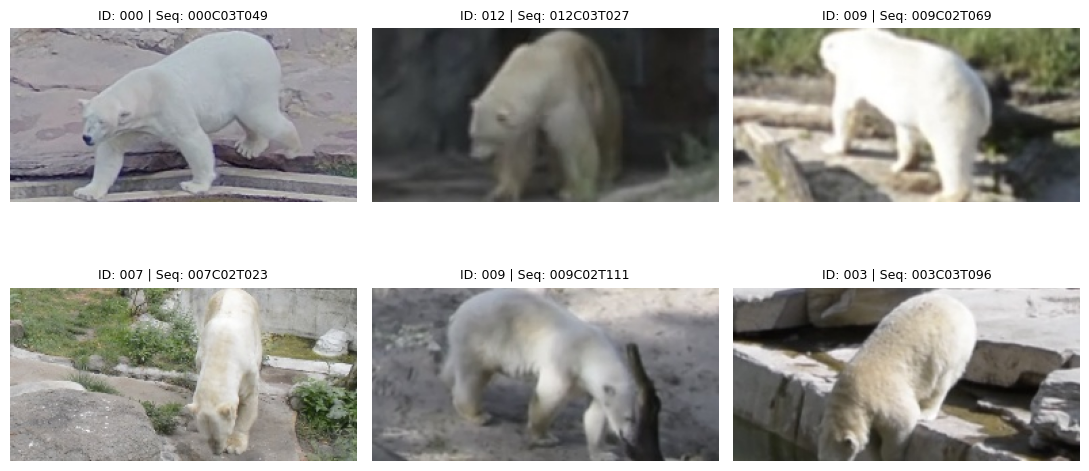

In [ ]:
sample_rows = manifest.sample(min(6, len(manifest)), random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
with zipfile.ZipFile(LOCAL_ZIP) as archive:
    for ax, row in zip(axes.ravel(), sample_rows.itertuples(index=False)):
        with archive.open(row.member) as fh:
            img = Image.open(fh).convert("RGB")
        ax.imshow(img); ax.set_title(f"ID: {row.identity} | Seq: {row.sequence}", fontsize=9)
        ax.axis("off")
for ax in axes.ravel()[len(sample_rows):]: ax.axis("off")
plt.tight_layout(); plt.show()

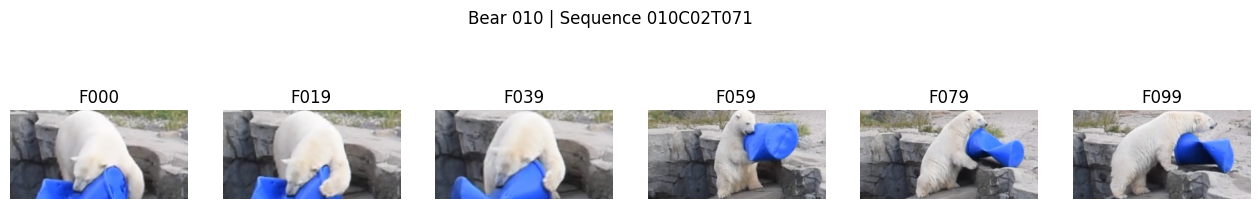

In [ ]:
# Check that each video sequence is one polar bear
# Select one random video sequence
grouped = manifest.groupby(["identity", "sequence"])
identity, sequence = random.choice(list(grouped.groups.keys()))
video = grouped.get_group((identity, sequence))

# Select up to 6 frames from that sequence
frames = video.sort_values("member")
indices = np.linspace(0, len(frames) - 1, min(6, len(frames)), dtype=int)
selected = frames.iloc[indices]

# Display the frames
fig, axes = plt.subplots(1, len(selected), figsize=(16, 3))
axes = np.atleast_1d(axes)
with zipfile.ZipFile(LOCAL_ZIP) as archive:
    for ax, path in zip(axes, selected["member"]):
        with archive.open(path) as f:
            ax.imshow(Image.open(f).convert("RGB"))
        ax.set_title(Path(path).stem[-4:])
        ax.axis("off")
plt.suptitle(f"Bear {identity} | Sequence {sequence}")
plt.show()

## 5. Sample up to 20 frames per video

Select evenly spaced frames from each video to reduce computation while covering different moments. Videos with fewer than 20 frames keep all their frames.

In [ ]:
sampled_groups = []

for _, video in manifest.groupby(["identity", "sequence"]):
    # Sort by actual frame number
    video = video.assign(
        frame_number=video["member"]
        .str.extract(r"F(\d+)\.", expand=False)
        .astype(int)
    ).sort_values("frame_number")

    # Select up to 20 evenly spaced frames
    n = min(FRAMES_PER_VIDEO, len(video))
    indices = np.linspace(0, len(video) - 1, n, dtype=int)
    sampled_groups.append(video.iloc[indices])

sampled_frames = pd.concat(sampled_groups, ignore_index=True)

print("Original frames:", len(manifest))
print("Selected frames:", len(sampled_frames))
print("Videos:", sampled_frames["sequence"].nunique())
display(sampled_frames.head())

Original frames: 138363
Selected frames: 28620
Videos: 1431


,member,identity,sequence,frame_number
0,000/000C01T000F000.jpg,000,000C01T000,0
1,000/000C01T000F005.jpg,000,000C01T000,5
2,000/000C01T000F010.jpg,000,000C01T000,10
3,000/000C01T000F015.jpg,000,000C01T000,15
4,000/000C01T000F020.jpg,000,000C01T000,20


### 5.1 Check the sampled frames
Display six of the selected frames from one video to inspect their order and coverage.

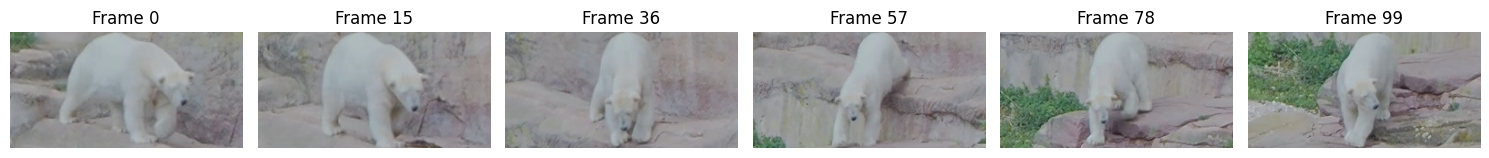

In [ ]:
video = next(iter(
    sampled_frames.groupby(["identity", "sequence"])
))[1]

preview = video.iloc[np.linspace(0, len(video) - 1, 6, dtype=int)]
fig, axes = plt.subplots(1, 6, figsize=(15, 3))

with zipfile.ZipFile(LOCAL_ZIP) as archive:
    for ax, row in zip(axes, preview.itertuples()):
        with archive.open(row.member) as file:
            ax.imshow(Image.open(file).convert("RGB"))
        ax.set_title(f"Frame {row.frame_number}")
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
nums = np.sort(video["frame_number"].to_numpy())
print("Number of frames:", len(nums))
print("Frame numbers:", nums)
print("Missing numbers:", sorted(set(range(nums[0], nums[-1] + 1)) - set(nums)))

Number of frames: 20
Frame numbers: [ 0  5 10 15 20 26 31 36 41 46 52 57 62 67 72 78 83 88 93 99]
Missing numbers: [1, 2, 3, 4, 6, 7, 8, 9, 11, 12, 13, 14, 16, 17, 18, 19, 21, 22, 23, 24, 25, 27, 28, 29, 30, 32, 33, 34, 35, 37, 38, 39, 40, 42, 43, 44, 45, 47, 48, 49, 50, 51, 53, 54, 55, 56, 58, 59, 60, 61, 63, 64, 65, 66, 68, 69, 70, 71, 73, 74, 75, 76, 77, 79, 80, 81, 82, 84, 85, 86, 87, 89, 90, 91, 92, 94, 95, 96, 97, 98]


In [ ]:
frame_counts = manifest.groupby(["identity", "sequence"]).size()

print("Total videos:", len(frame_counts))
print("Fewest frames:", frame_counts.min())
print("Most frames:", frame_counts.max())
print("Videos with fewer than 20 frames:", (frame_counts < 20).sum())

Total videos: 1431
Fewest frames: 28
Most frames: 100
Videos with fewer than 20 frames: 0


### Prepare train/val/test

In [ ]:
videos = (
    manifest[["identity", "sequence"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total videos:", len(videos))
display(videos.head())

Total videos: 1431


,identity,sequence
0,000,000C01T000
1,000,000C01T004
2,000,000C01T005
3,000,000C01T009
4,000,000C01T010


In [ ]:
from sklearn.model_selection import train_test_split

train_videos, remaining = train_test_split(
    videos, test_size=0.4,
    stratify=videos["identity"], random_state=42
)

val_videos, test_videos = train_test_split(
    remaining, test_size=0.5,
    stratify=remaining["identity"], random_state=42
)

print("Train:", len(train_videos))
print("Validation:", len(val_videos))
print("Test:", len(test_videos))

Train: 858
Validation: 286
Test: 287


In [ ]:
splits = {
    "train": train_videos,
    "validation": val_videos,
    "test": test_videos
}

keys = {
    name: set(zip(df["identity"], df["sequence"]))
    for name, df in splits.items()
}

assert keys["train"].isdisjoint(keys["validation"])
assert keys["train"].isdisjoint(keys["test"])
assert keys["validation"].isdisjoint(keys["test"])
assert set.union(*keys.values()) == set(
    zip(videos["identity"], videos["sequence"])
)

for name, df in splits.items():
    assert df["identity"].nunique() == 13
    print(f"{name}: {len(df)} videos, 13 bears")

print("PASS: complete coverage and no overlapping videos.")

train: 858 videos, 13 bears
validation: 286 videos, 13 bears
test: 287 videos, 13 bears
PASS: complete coverage and no overlapping videos.


In [ ]:
split_labels = pd.concat(
    [df.assign(split=name) for name, df in splits.items()],
    ignore_index=True
)

manifest = manifest.merge(
    split_labels,
    on=["identity", "sequence"],
    how="left",
    validate="many_to_one"
)

assert manifest["split"].notna().all()
print(manifest["split"].value_counts())
display(manifest.head())

split
train         82869
test          27887
validation    27607
Name: count, dtype: int64


,member,identity,sequence,split
0,000/000C01T000F000.jpg,000,000C01T000,train
1,000/000C01T000F001.jpg,000,000C01T000,train
2,000/000C01T000F002.jpg,000,000C01T000,train
3,000/000C01T000F003.jpg,000,000C01T000,train
4,000/000C01T000F004.jpg,000,000C01T000,train


In [ ]:
sampled_frames = []

for _, group in manifest.groupby(["identity", "sequence"]):
    group = group.sort_values(
        "member",
        key=lambda s: s.str.extract(r"F(\d+)", expand=False).astype(int)
    )
    indices = np.linspace(0, len(group) - 1, 20, dtype=int)
    sampled_frames.append(group.iloc[indices])

sampled = pd.concat(sampled_frames, ignore_index=True)

print("Selected frames:", len(sampled))
print(sampled["split"].value_counts())

Selected frames: 28620
split
train         17160
test           5740
validation     5720
Name: count, dtype: int64


## Feature Extraction with MegaDescriptor
Convert each selected frame into an embedding using the frozen pretrained model.

In [ ]:
import timm
from torchvision import transforms as T

model = timm.create_model(
    "hf-hub:BVRA/MegaDescriptor-S-224", pretrained=True
).to(DEVICE).eval()

model.requires_grad_(False)

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.5] * 3, [0.5] * 3)
])

print("Model loaded on:", DEVICE)

Model loaded on: cpu


In [ ]:
from tqdm.auto import tqdm

parts = []

with zipfile.ZipFile(LOCAL_ZIP) as archive:
    for start in tqdm(range(0, len(sampled), BATCH_SIZE)):
        images = []
        for path in sampled["member"].iloc[start:start + BATCH_SIZE]:
            with archive.open(path) as file:
                images.append(transform(Image.open(file).convert("RGB")))

        batch = torch.stack(images).to(DEVICE)
        with torch.inference_mode():
            parts.append(model(batch).cpu())

embeddings = torch.cat(parts).numpy()
assert len(embeddings) == len(sampled)
assert np.isfinite(embeddings).all()
print("Completed:", embeddings.shape)

  0%|          | 0/3578 [00:00<?, ?it/s]

Completed: (28620, 768)


In [ ]:
save_path = OUTPUT_DIR / "polarbear_frame_embeddings.npz"

np.savez_compressed(
    save_path,
    embeddings=embeddings,
    **{col: sampled[col].to_numpy(dtype=str)
       for col in ["member", "identity", "sequence", "split"]}
)

print("Saved:", save_path)

Saved: /content/reid_results/polarbear_frame_embeddings.npz
